In [1]:
library(report)
library(lme4)
library(lmerTest)
library(BayesFactor)
source('bayesMannWhitney.R')

Loading required package: Matrix


Attaching package: ‘lmerTest’


The following object is masked from ‘package:lme4’:

    lmer


The following object is masked from ‘package:stats’:

    step


Loading required package: coda

************
Welcome to BayesFactor 0.9.12-4.4. If you have questions, please contact Richard Morey (richarddmorey@gmail.com).

Type BFManual() to open the manual.
************



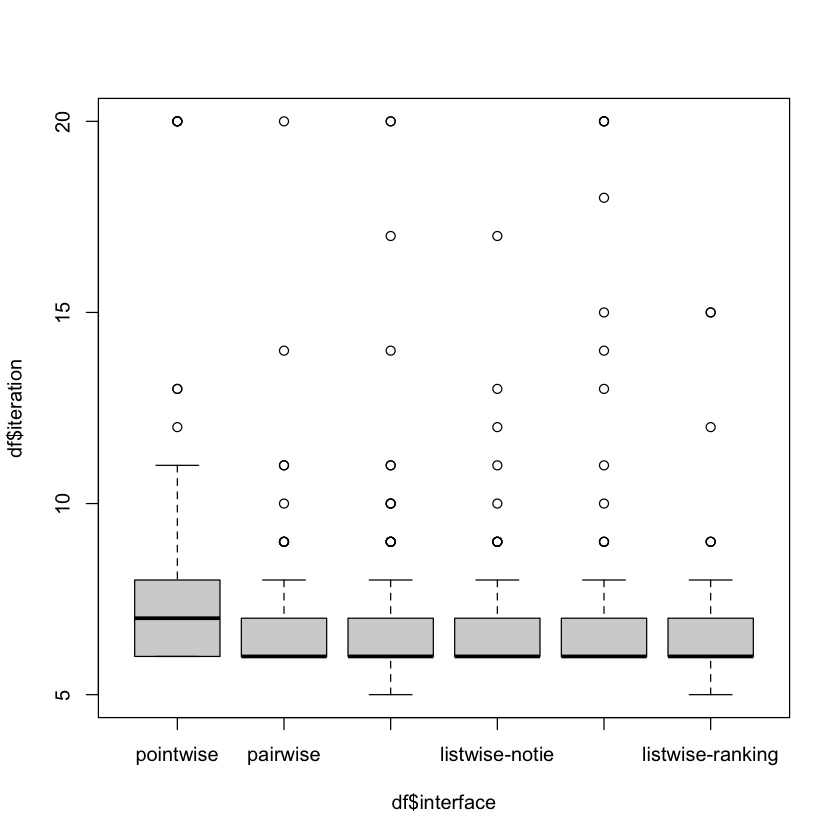

In [2]:
df <- read.csv('processed/iterations.csv')
df$interface = factor(df$interface, levels = c('pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking'), ordered=FALSE)
boxplot(df$iteration ~ df$interface)

In [3]:
# H1
df1 <- df[df$interface == 'pointwise',]
df2 <- df[df$interface == 'pairwise',]
r <- report(wilcox.test(df1$iteration, df2$iteration))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$iteration and df2$iteration suggests that the effect is
positive, statistically significant, and medium (W = 4920.00, p = 0.007; r
(rank biserial) = 0.21, 95% CI [0.05, 0.37])


In [4]:
# H2a
df1 <- df[df$interface == 'pointwise',]
df2 <- df[df$interface == 'listwise-rating',]
r <- report(wilcox.test(df1$iteration, df2$iteration))
print(r, verbose=TRUE)

# H2a
df1 <- df[df$interface == 'pairwise',]
df2 <- df[df$interface == 'listwise-cantie',]
r <- report(wilcox.test(df1$iteration, df2$iteration))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$iteration and df2$iteration suggests that the effect is
positive, statistically significant, and small (W = 4718.00, p = 0.028; r (rank
biserial) = 0.18, 95% CI [0.01, 0.34])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$iteration and df2$iteration suggests that the effect is
positive, statistically not significant, and very small (W = 4253.00, p =
0.506; r (rank biserial) = 0.05, 95% CI [-0.12, 0.22])


  |**************************************************| 100%

[1] 0.1884032

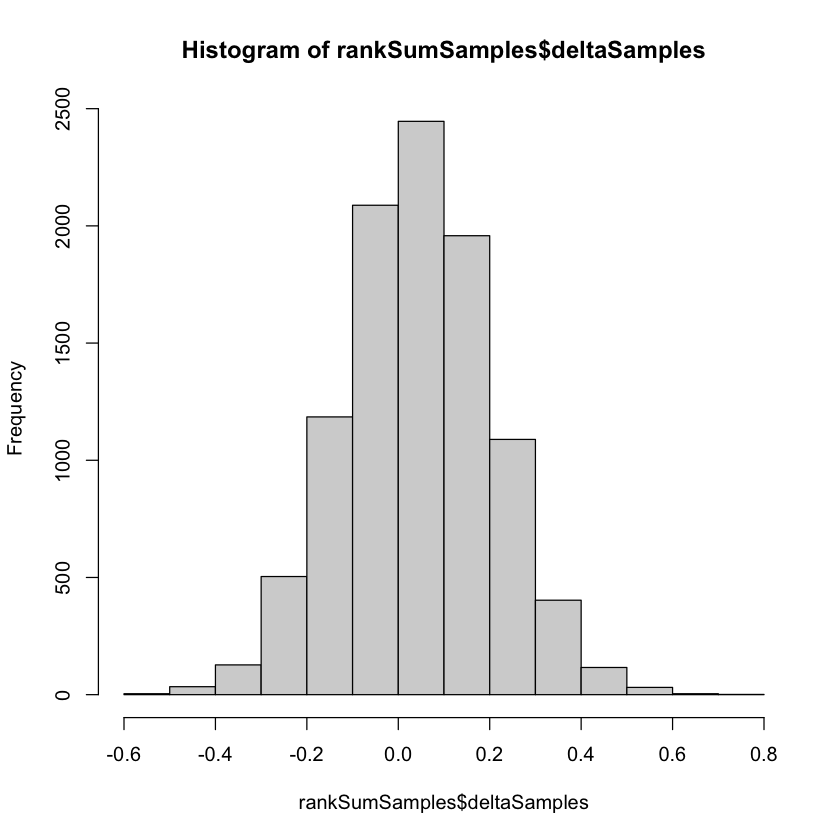

In [5]:
x <- df1$iteration
y <- df2$iteration

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [6]:
df <- read.csv("processed/iterations.csv")
df <- df[df$interface != 'pointwise',]
df <- df[df$interface != 'pairwise',]
df <- df[df$interface != 'listwise-ranking',]

df$interface <- factor(df$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
# H3
m <- glmer(iteration ~ interface + (1|userID), data = df, family = poisson)
summary(m)
print(report(m), verbose=TRUE)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: poisson  ( log )
Formula: iteration ~ interface + (1 | userID)
   Data: df

     AIC      BIC   logLik deviance df.resid 
  1206.6   1221.0   -599.3   1198.6      265 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.8683 -0.3699 -0.2546  0.0087  4.1066 

Random effects:
 Groups Name        Variance Std.Dev.
 userID (Intercept) 0.01775  0.1332  
Number of obs: 269, groups:  userID, 90

Fixed effects:
                           Estimate Std. Error z value Pr(>|z|)    
(Intercept)               1.9777381  0.0463245  42.693   <2e-16 ***
interfacelistwise-rating -0.0008386  0.0652614  -0.013    0.990    
interfacelistwise-notie  -0.0648466  0.0659157  -0.984    0.325    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.704              
intrfclstws-n -0.698  0.493       

We fitted a poisson mixed model (estimated using ML and Nelder-Mead optimizer)
to predict iteration with interface
 (formula: iteration ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
weak (conditional R2 = 0.12) and the part related to the fixed effects alone
(marginal R2) is of 6.14e-03. The model's intercept, corresponding to interface
= listwise-cantie
, is at 1.98 (95% CI [1.89, 2.07], p < .001). Within this model:

  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -8.39e-04, 95% CI [-0.13, 0.13], p = 0.990; Std. beta =
-8.39e-04, 95% CI [-0.13, 0.13])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = -0.06, 95% CI [-0.19, 0.06], p = 0.325; Std. beta = -0.06, 95%
CI [-0.19, 0.06])

Standardized parameters were obtained by fitting the model on a standardized
version of the dataset. 95% Confidence Intervals (CIs) 

In [7]:
df <- read.csv("processed/iterations.csv")
df <- df[df$interface != 'pointwise',]

df$interface <- factor(df$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
# H4
m <- glmer(iteration ~ interface + (1|userID), data = df, family = poisson)
summary(m)
print(report(m), verbose=TRUE)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: poisson  ( log )
Formula: iteration ~ interface + (1 | userID)
   Data: df

     AIC      BIC   logLik deviance df.resid 
  1959.3   1984.0   -973.7   1947.3      443 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-0.7993 -0.4086 -0.2873  0.0365  4.6950 

Random effects:
 Groups Name        Variance Std.Dev.
 userID (Intercept) 0.004124 0.06422 
Number of obs: 449, groups:  userID, 150

Fixed effects:
                         Estimate Std. Error z value Pr(>|z|)    
(Intercept)               1.89683    0.04252  44.615   <2e-16 ***
interfacepairwise         0.04233    0.05945   0.712    0.476    
interfacelistwise-rating  0.08635    0.05901   1.463    0.143    
interfacelistwise-notie   0.02139    0.05973   0.358    0.720    
interfacelistwise-cantie  0.09021    0.05882   1.534    0.125    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation o

We fitted a poisson mixed model (estimated using ML and Nelder-Mead optimizer)
to predict iteration with interface
 (formula: iteration ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
weak (conditional R2 = 0.04) and the part related to the fixed effects alone
(marginal R2) is of 9.07e-03. The model's intercept, corresponding to interface
= listwise-ranking
, is at 1.90 (95% CI [1.81, 1.98], p < .001). Within this model:

  - The effect of interface [pairwise] is statistically non-significant and
positive (beta = 0.04, 95% CI [-0.07, 0.16], p = 0.476; Std. beta = 0.04, 95%
CI [-0.07, 0.16])
  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 0.09, 95% CI [-0.03, 0.20], p = 0.143; Std. beta = 0.09,
95% CI [-0.03, 0.20])
  - The effect of interface [listwise-notie] is statistically non-significant and
positive (beta = 0.02, 95% CI [-0.10, 0.14], p = 0.720; Std. beta = 